# Experiment 3 — Feature only baselines
Train the simple group separately under C0, C1, and C2. Train the identical
complex group once per seed and reuse it for all three input conditions.
That is **20 baseline runs** with five seeds: four distinct groups × five seeds.
All use alpha 1, width 32, learning rate 0.03, and 500 updates, matching Notebook 02.
Separate learnability does not guarantee selection when groups compete.

In [1]:
from pathlib import Path
import sys, json, inspect
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

# Works when Jupyter starts inside experiment_3 or its parent project folder.
ROOT = Path.cwd()
if not (ROOT / 'experiment.py').exists():
    ROOT = ROOT / 'experiment_3'
assert (ROOT / 'experiment.py').exists(), 'Start Jupyter in experiment_3 or its parent folder.'
sys.path.insert(0, str(ROOT))
from experiment import (DATASETS, CONDITIONS, ALPHAS, SEEDS, make_splits, input_data,
    make_model, make_base, complex_columns, initial_checks, classification_metrics,
    conflict_metrics, counterfactual_metrics, train_model, compare_snapshots,
    settings, save_splits, save_json, save_rows, baseline_data, make_baseline,
    INITIAL_TOLERANCE, TRAJECTORY_TOLERANCE)

# Small matrix operations are usually faster with one CPU thread here.
torch.set_num_threads(1)
splits = make_splits()
print('Experiment folder:', ROOT)
print('PyTorch:', torch.__version__)

Experiment folder: c:\Users\ESHAAN\HAKUR\SimpBias\experiment_3
PyTorch: 2.14.1+cpu


In [2]:
QUICK_RUN = False  # True: one seed and 25 updates; saves only to results/preview.
SHOW_LIVE = True
config = settings(QUICK_RUN)
RESULTS = ROOT / 'results' / 'preview' if QUICK_RUN else ROOT / 'results'
print(config)

{'seeds': [42, 43, 44, 45, 46], 'alphas': [0.1, 0.5, 1.0, 2.0, 5.0, 10.0], 'steps': 500, 'lr': 0.03, 'quick': False}


## Baseline inputs and initialization
Simple inputs are [AT], [AT,0], and [AT,R]. Their shared weights, biases, and
output layer are copied from a one-input reference. The added baseline column
uses Uniform(-1,1), matching that reference's initialization bound. C1 and C2
share this column. The complex baseline uses [BU,CUT]. No compensation is needed
at alpha 1. These capability baselines have their own input-width initialization;
they are not initialization-matched to the joint model.

In [4]:
def show_training(key, history):
    if not SHOW_LIVE or (history[-1]['step'] % 100 and history[-1]['step'] != config['steps']):
        return
    frame = pd.DataFrame(history)
    clear_output(wait=True)
    has_conflicts = 'complex_conflict_agreement' in frame
    fig, axes = plt.subplots(1, 3 if has_conflicts else 2, figsize=(13, 3.3))
    for split in ['train', 'validation']:
        axes[0].plot(frame.step, frame[f'{split}_loss'], label=split)
        axes[1].plot(frame.step, frame[f'{split}_accuracy'], label=split)
    axes[0].set(title='BCE loss', xlabel='Update')
    axes[1].set(title='Accuracy', xlabel='Update', ylim=(-0.05, 1.05))
    if has_conflicts:
        axes[2].plot(frame.step, frame.complex_conflict_agreement)
        axes[2].set(title='Complex conflict agreement', xlabel='Update', ylim=(-0.05, 1.05))
    for ax in axes:
        ax.grid(alpha=0.2)
    axes[0].legend(); axes[1].legend()
    title = ' | '.join(f'{k}: {v}' for k, v in key.items() if k != 'run_id')
    fig.suptitle(title + f" | step {history[-1]['step']}/{config['steps']}")
    fig.tight_layout(); display(fig); plt.close(fig)

## Train and watch progress
Only training loss supplies gradients. Validation is monitored without early
stopping. Test metrics are computed at the fixed final update. Saved files are
feature_only.csv, feature_only_history.csv, and baseline_settings.json.

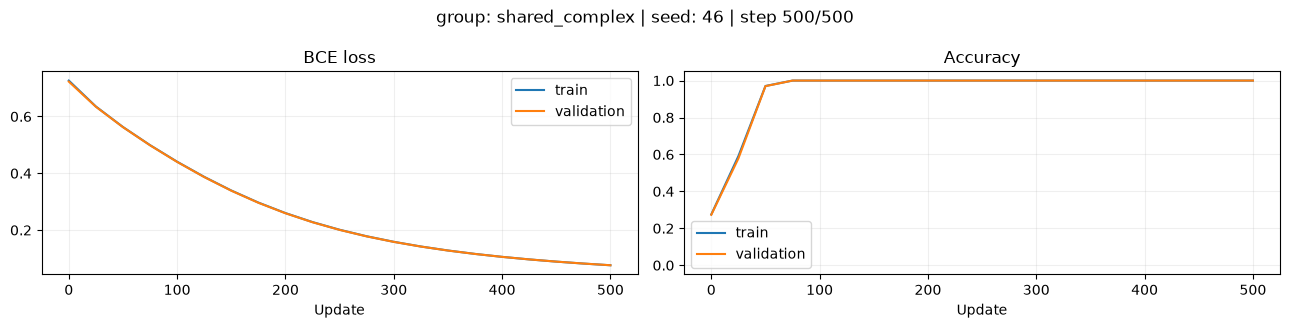

20/20: shared_complex, seed 46, test 1.000


train_accuracy      validation_accuracy      test_accuracy  \
                         mean  std                mean  std          mean   
group                                                                       
C0_simple                 1.0  0.0                 1.0  0.0           1.0   
C1_simple                 1.0  0.0                 1.0  0.0           1.0   
C2_simple                 1.0  0.0                 1.0  0.0           1.0   
shared_complex            1.0  0.0                 1.0  0.0           1.0   

                    test_loss            
                std      mean       std  
group                                    
C0_simple       0.0  0.015058  0.000582  
C1_simple       0.0  0.015058  0.000582  
C2_simple       0.0  0.018550  0.001505  
shared_complex  0.0  0.089268  0.010610

In [5]:
groups = ['C0_simple', 'C1_simple', 'C2_simple', 'shared_complex']
baseline_rows, baseline_history = [], []
save_json(RESULTS / 'baseline_settings.json', dict(config, status='running'))

for seed in config['seeds']:
    for group in groups:
        data = {name: baseline_data(value,group) for name,value in splits.items() if name != 'conflicts'}
        model = make_baseline(seed,group)
        key = {'group':group, 'seed':seed}
        callback = (lambda history: show_training(key,history)) if SHOW_LIVE else None
        history, _ = train_model(model,data['train'],data['validation'],
                                  steps=config['steps'],lr=config['lr'],on_log=callback)
        row = dict(key, **history[-1])
        row.update({f'test_{k}':v for k,v in classification_metrics(model,data['test']).items()})
        baseline_rows.append(row)
        baseline_history.extend(dict(key,**r) for r in history)
        # Save after each model, so completed work is visible if a run stops.
        save_rows(RESULTS / 'feature_only.csv',baseline_rows)
        save_rows(RESULTS / 'feature_only_history.csv',baseline_history)
        print(f"{len(baseline_rows)}/{4*len(config['seeds'])}: {group}, seed {seed}, test {row['test_accuracy']:.3f}")

save_json(RESULTS / 'baseline_settings.json',dict(config,status='complete'))
baseline = pd.DataFrame(baseline_rows)
display(baseline.groupby('group')[['train_accuracy','validation_accuracy','test_accuracy','test_loss']].agg(['mean','std']))

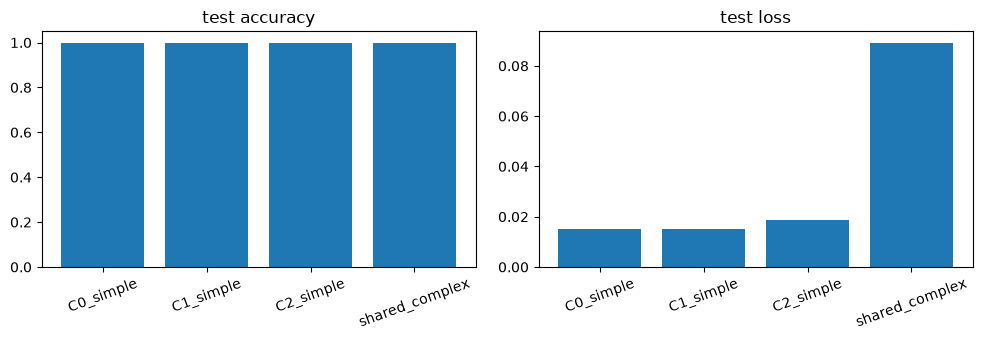

Every baseline learned perfectly: True
Inspect failures before interpreting joint preference; do not presume baseline success.


In [6]:
fig, axes = plt.subplots(1,2,figsize=(10,3.5))
grouped = baseline.groupby('group')
for ax, metric in zip(axes,['test_accuracy','test_loss']):
    means = grouped[metric].mean()
    ax.bar(means.index, means)
    ax.set(title=metric.replace('_',' ')); ax.tick_params(axis='x',rotation=20)
fig.tight_layout(); plt.show()
print('Every baseline learned perfectly:', bool((baseline.test_accuracy == 1).all()))
print('Inspect failures before interpreting joint preference; do not presume baseline success.')